# Лабораторная работа 2: «Разработка сверточной нейронной сети с использованием PyTorch»
Пушкарев Илья 3825М1ПМкн1

Зависимости

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)                  # фиксируем зерно генераторов
np.random.seed(42)                     # для воспроизводимости результатов
torch.backends.cudnn.benchmark = True  # ускоряет свёртки на GPU

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Устройство вычислений:", DEVICE)

PyTorch: 2.15.0+cpu
Устройство вычислений: cpu


Загружаем датасет CIFAR-10

CIFAR-10 — 60 000 цветных изображений 32×32 из 10 классов (самолёт, автомобиль, птица, кошка, олень, собака, лягушка, лошадь, корабль, грузовик). Выборка делится на обучение (50 000) и тест (10 000); torchvision скачивает набор автоматически.

In [2]:
DATA_DIR = "./data"

train_raw = datasets.CIFAR10(DATA_DIR, train=True, download=True)   # без преобразований — для просмотра
test_raw = datasets.CIFAR10(DATA_DIR, train=False, download=True)
print("Каталог с данными:", os.path.abspath(train_raw.root))

Каталог с данными: /home/z/my-project/work/data


Свойства данных

Обучающая выборка: 50000 изображений
Тестовая выборка:  10000 изображений
Форма одного изображения: 32 x 32 пикселей, 3 цветовых канала (RGB)
Форма массива изображений train: (50000, 32, 32, 3), dtype: uint8
Форма массива меток train: (50000,), dtype: int64
Число классов: 10
Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Число примеров по классам train: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


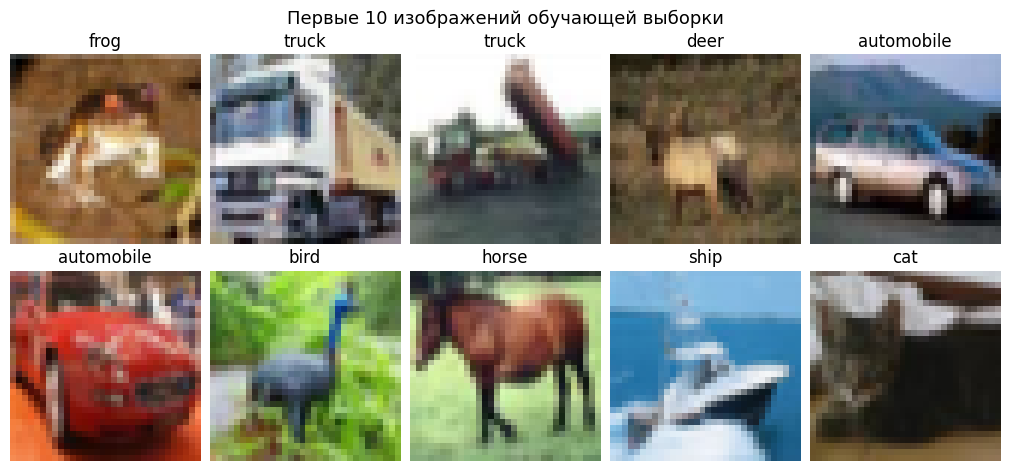

In [3]:
CLASSES = train_raw.classes

print(f"Обучающая выборка: {train_raw.data.shape[0]} изображений")
print(f"Тестовая выборка:  {test_raw.data.shape[0]} изображений")
print(f"Форма одного изображения: {train_raw.data.shape[1]} x {train_raw.data.shape[2]} пикселей, "
      f"{train_raw.data.shape[3]} цветовых канала (RGB)")
print(f"Форма массива изображений train: {train_raw.data.shape}, dtype: {train_raw.data.dtype}")
print(f"Форма массива меток train: {np.array(train_raw.targets).shape}, dtype: {np.array(train_raw.targets).dtype}")
print(f"Число классов: {len(CLASSES)}")
print(f"Классы: {CLASSES}")
print(f"Число примеров по классам train: {np.bincount(train_raw.targets)}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.6), constrained_layout=True)
for ax, img, label in zip(axes.flat, train_raw.data[:10], train_raw.targets[:10]):
    ax.imshow(img)
    ax.set_title(CLASSES[label])
    ax.axis("off")
fig.suptitle("Первые 10 изображений обучающей выборки", fontsize=13)
plt.show()

Подготовка данных

- **Нормализация** — пиксели приводим к диапазону [0, 1], затем вычитаем среднее и делим на СКО каждого канала (статистики считаем по обучающей выборке): признаки получают нулевое среднее и единичный масштаб, что ускоряет и стабилизирует обучение.
- **Аугментация** — при выдаче каждой обучающей картинки случайно сдвигаем её на ±4 пикселя (`RandomCrop(32, padding=4)`) и с вероятностью 0.5 отражаем по горизонтали. Сеть почти каждый раз видит «новые» варианты тех же изображений — это сдерживает переобучение и повышает итоговую точность. Тестовая выборка не аугментируется.
- **Пачки** — `DataLoader` выдаёт изображения пачками по 128; обучающие каждую эпоху перемешиваются.

In [4]:
data = train_raw.data.astype(np.float32) / 255.0
MEAN = tuple(data.mean(axis=(0, 1, 2)))
STD = tuple(data.std(axis=(0, 1, 2)))
print(f"Среднее каналов RGB: {tuple(round(float(m), 4) for m in MEAN)}")
print(f"СКО каналов RGB:     {tuple(round(float(s), 4) for s in STD)}")

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),   # аугментация: случайный сдвиг
    transforms.RandomHorizontalFlip(),      # аугментация: случайное отражение
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),        # нормализация
])
test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=train_tf)
train_eval_ds = datasets.CIFAR10(DATA_DIR, train=True, download=False, transform=test_tf)  # train без аугментации — для честной оценки
test_ds = datasets.CIFAR10(DATA_DIR, train=False, download=False, transform=test_tf)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, persistent_workers=True)
train_eval_loader = DataLoader(train_eval_ds, batch_size=512, shuffle=False,
                               num_workers=2, persistent_workers=True)
test_loader = DataLoader(test_ds, batch_size=512, shuffle=False,
                         num_workers=2, persistent_workers=True)

images, labels = next(iter(train_loader))
print(f"Пачка изображений: {tuple(images.shape)} | пачка меток: {tuple(labels.shape)}")
print(f"Итераций обучения в эпохе: {len(train_loader)}")

Среднее каналов RGB: (0.4914, 0.4822, 0.4465)
СКО каналов RGB:     (0.247, 0.2435, 0.2616)


Пачка изображений: (128, 3, 32, 32) | пачка меток: (128,)
Итераций обучения в эпохе: 391


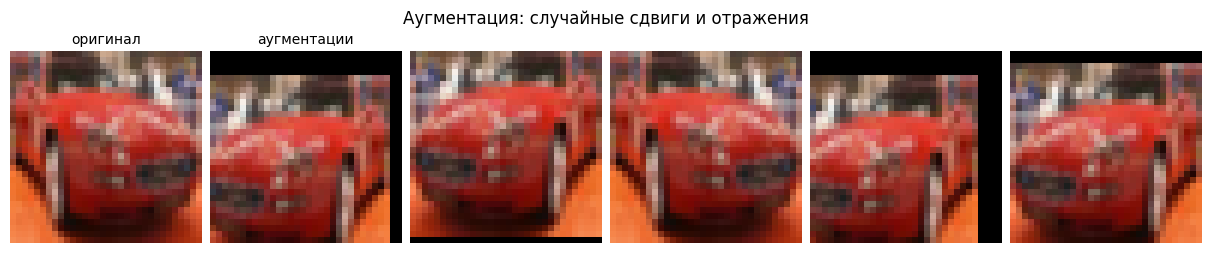

In [5]:
# Наглядно: одна картинка и её аугментированные версии
to_pil = transforms.ToPILImage()
img_pil = to_pil(train_raw.data[5])

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5), constrained_layout=True)
axes[0].imshow(train_raw.data[5])
axes[0].set_title("оригинал", fontsize=10)
axes[0].axis("off")
for ax in axes[1:]:
    t = train_tf(img_pil)                                                   # аугментация + нормализация
    img = t * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)  # отменяем нормализацию
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.axis("off")
axes[1].set_title("аугментации", fontsize=10)
fig.suptitle("Аугментация: случайные сдвиги и отражения", fontsize=12)
plt.show()

Архитектура сети

Реализуем сеть вида **ResNet-20** — классический CIFAR-вариант ResNet (He et al., 2016, «Deep Residual Learning for Image Recognition»):

- стволовой слой: свёртка 3×3 (3 → 16 каналов) + BatchNorm + ReLU;
- 3 стадии по 3 остаточных блока; на входе каждой новой стадии число каналов удваивается (16 → 32 → 64), а размер карты признаков уменьшается вдвое (шаг свёртки stride=2);
- **остаточный блок**: два слоя «свёртка 3×3 + BatchNorm» и skip-connection, складывающая вход блока с его выходом; ReLU в конце. Такой «короткий путь» даёт градиенту прямой маршрут к ранним слоям — глубокие сети обучаются быстро и устойчиво;
- глобальный average pooling сводит каждую карту признаков 8×8 к одному числу, полносвязный слой выдаёт 10 логитов классов (softmax применяется внутри функции потерь).

Сеть описана собственным классом и собрана только из базовых слоёв PyTorch (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.Linear` и т.д.) — готовые архитектуры из `torchvision.models` и других источников не используются (требование методички).

In [6]:
class ResidualBlock(nn.Module):
    """Остаточный блок: conv3x3-BN-ReLU-conv3x3-BN + skip-connection, ReLU на выходе."""

    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        # если меняется число каналов или размер карты — приводим shortcut свёрткой 1x1
        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.shortcut(x))


class CifarResNet(nn.Module):
    """ResNet-20 для CIFAR: stem -> 3 стадии остаточных блоков -> global average pooling -> линейный слой."""

    def __init__(self, widths=(16, 32, 64), blocks=(3, 3, 3), n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )
        stages, ch = [], widths[0]
        for w, n in zip(widths, blocks):
            for _ in range(n):
                stages.append(ResidualBlock(ch, w, stride=2 if w != ch else 1))
                ch = w
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),      # (B, C, 1, 1) — по одному числу на карту признаков
            nn.Flatten(),
            nn.Linear(ch, n_classes),     # логиты классов
        )

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))

model = CifarResNet().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Число обучаемых параметров: {n_params:,}".replace(",", " "))

with torch.inference_mode():
    probe = model(images[:4].to(DEVICE))
print("Форма выхода на пачке из 4 изображений:", tuple(probe.shape), "— по числу классов")

Число обучаемых параметров: 272 474
Форма выхода на пачке из 4 изображений: (4, 10) — по числу классов


Функция потерь и оптимизатор

**Функция потерь** — кросс-энтропия: `nn.CrossEntropyLoss` объединяет softmax и кросс-энтропию — ту же функцию ошибки, которую мы выводили и реализовывали вручную в лабораторной работе 1.

**Оптимизатор** — SGD с моментом (`momentum=0.9`): момент ускоряет движение в устойчивом направлении и гасит осцилляции. `weight_decay=5e-4` — L2-штраф на большие веса, сдерживает переобучение. Скорость обучения стартует с 0.1 и убывает по **cosine-расписанию** до нуля к концу обучения: в начале большие шаги быстро выводят в хорошую область, в конце мелкие шаги точно донастраивают веса.

In [7]:
EPOCHS = 20  # число эпох
LEARNING_RATE = 0.1    # начальная скорость обучения
WEIGHT_DECAY = 5e-4    # коэффициент L2-регуляризации

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE,
                            momentum=0.9, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def train_epoch(model, loader):
    """Одна эпоха SGD по пачкам; возвращает средний loss и точность за эпоху."""
    model.train()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    return total_loss / seen, correct / seen


@torch.inference_mode()
def evaluate(model, loader):
    """Прямой проход без обучения; возвращает средний loss и точность."""
    model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        seen += len(labels)
    return total_loss / seen, correct / seen

history = {"loss": [], "train_acc": [], "test_loss": [], "test_acc": [],
           "epoch_time": [], "lr": []}

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    loss, _ = train_epoch(model, train_loader)          # обучение эпохи
    _, train_acc = evaluate(model, train_eval_loader)   # честная оценка на train (без аугментации)
    test_loss, test_acc = evaluate(model, test_loader)  # оценка на test
    epoch_time = time.perf_counter() - epoch_start

    history["loss"].append(loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    history["epoch_time"].append(epoch_time)
    history["lr"].append(scheduler.get_last_lr()[0])

    print(f"Эпоха {epoch:2d}/{EPOCHS} | время: {epoch_time:6.1f} с | lr: {history['lr'][-1]:.4f} | "
          f"loss: {loss:.4f} | точность train: {train_acc * 100:5.2f}% | ошибка train: {(1 - train_acc) * 100:5.2f}% | "
          f"точность test: {test_acc * 100:5.2f}% | ошибка test: {(1 - test_acc) * 100:5.2f}%", flush=True)
    scheduler.step()

history["total_time"] = float(np.sum(history["epoch_time"]))
print(f"\nОбщее время обучения: {history['total_time']:.1f} с")

Эпоха  1/20 | время:  184.1 с | lr: 0.1000 | loss: 1.6918 | точность train: 48.62% | ошибка train: 51.38% | точность test: 49.48% | ошибка test: 50.52%
Эпоха  2/20 | время:  185.2 с | lr: 0.0994 | loss: 1.2304 | точность train: 58.59% | ошибка train: 41.41% | точность test: 57.82% | ошибка test: 42.18%
Эпоха  3/20 | время:  179.5 с | lr: 0.0976 | loss: 0.9748 | точность train: 63.65% | ошибка train: 36.35% | точность test: 63.20% | ошибка test: 36.80%
Эпоха  4/20 | время:  175.3 с | lr: 0.0946 | loss: 0.8355 | точность train: 59.27% | ошибка train: 40.73% | точность test: 58.79% | ошибка test: 41.21%
Эпоха  5/20 | время:  183.0 с | lr: 0.0905 | loss: 0.7282 | точность train: 69.53% | ошибка train: 30.47% | точность test: 68.67% | ошибка test: 31.33%
Эпоха  6/20 | время:  186.2 с | lr: 0.0854 | loss: 0.6680 | точность train: 77.66% | ошибка train: 22.34% | точность test: 75.93% | ошибка test: 24.07%
Эпоха  7/20 | время:  188.8 с | lr: 0.0794 | loss: 0.6225 | точность train: 77.82% | оши

Итоговая оценка на тестовой выборке

Сеть оцениваем на отложенной тестовой выборке из 10 000 изображений — она не участвовала ни в обучении, ни в подборе гиперпараметров. Дополнительно выводим точность по каждому классу.

In [8]:
all_preds, all_labels = [], []
model.eval()
with torch.inference_mode():
    for images, labels in test_loader:
        all_preds.append(model(images.to(DEVICE)).argmax(dim=1).cpu())
        all_labels.append(labels)
all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

accuracy = (all_preds == all_labels).mean()
print(f"Точность классификации на тестовой выборке: {accuracy * 100:.2f}%")
print(f"Ошибка классификации на тестовой выборке:   {(1 - accuracy) * 100:.2f}%")

print("\nТочность по классам:")
for c, name in enumerate(CLASSES):
    mask = all_labels == c
    print(f"  {name:<10} {(all_preds[mask] == c).mean() * 100:5.1f}%")

Точность классификации на тестовой выборке: 89.17%
Ошибка классификации на тестовой выборке:   10.83%

Точность по классам:
  airplane    91.8%
  automobile  94.8%
  bird        86.0%
  cat         73.7%
  deer        90.6%
  dog         85.0%
  frog        90.9%
  horse       92.1%
  ship        93.9%
  truck       92.9%


График изменения ошибки в процессе обучения

По истории обучения строим два графика: слева — значение функции ошибки (кросс-энтропии) на train и test после каждой эпохи, справа — точность классификации.

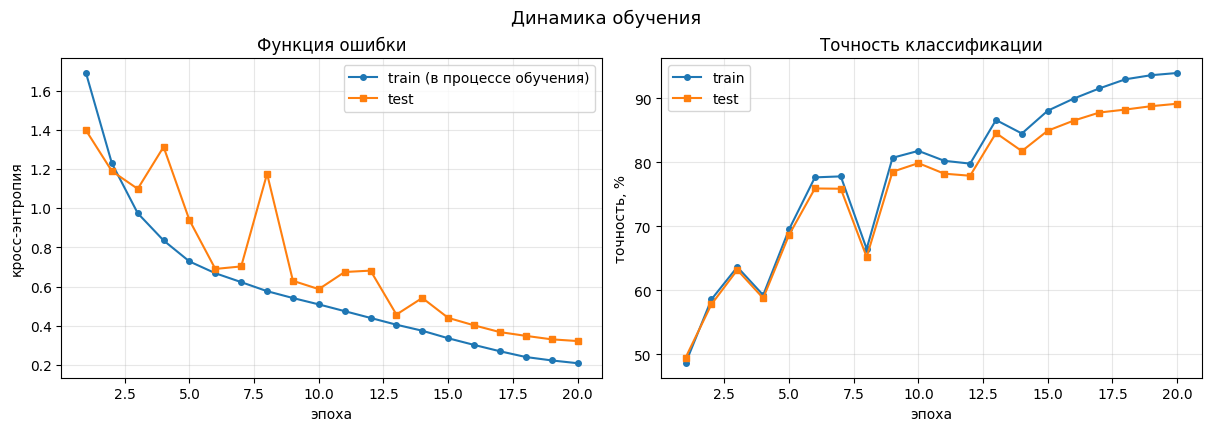

In [9]:
epochs_range = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

axes[0].plot(epochs_range, history["loss"], marker="o", ms=4, label="train (в процессе обучения)")
axes[0].plot(epochs_range, history["test_loss"], marker="s", ms=4, label="test")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("кросс-энтропия")
axes[0].set_title("Функция ошибки")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_range, 100 * np.array(history["train_acc"]), marker="o", ms=4, label="train")
axes[1].plot(epochs_range, 100 * np.array(history["test_acc"]), marker="s", ms=4, label="test")
axes[1].set_xlabel("эпоха")
axes[1].set_ylabel("точность, %")
axes[1].set_title("Точность классификации")
axes[1].grid(alpha=0.3)
axes[1].legend()

fig.suptitle("Динамика обучения", fontsize=13)
plt.show()